In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

attr = pd.read_csv('list_attr_celeba.csv')
bbox = pd.read_csv('list_bbox_celeba.csv')
landmark = pd.read_csv('list_landmarks_align_celeba.csv')
partition = pd.read_csv('list_eval_partition.csv')

print("=== IDENTIFIKASI DATASET ===")
print("Nama Dataset: CelebA Dataset")
print("Sumber: Kaggle - jessicali9530/celeba-dataset")
print("Jenis Data: Image / Gambar Wajah + Tabel (Multitable)")
print(f"Jumlah Data (foto): {attr.shape[0]}")
print(f"Jumlah Variabel Atribut: {attr.shape[1]-1}")
print(f"Nama Tabel: list_attr, list_bbox, list_landmarks, list_eval_partition")
print(f"Data Fitur (X): bbox + landmark (posisi wajah, mata, hidung, mulut)")
print(f"Data Target (y): ['Smiling','Male','Eyeglasses','Wearing_Hat','Young']")
print("\nKESIMPULAN SEMENTARA: Klasifikasi MULTILABEL")
print(attr.head(2))

=== IDENTIFIKASI DATASET ===
Nama Dataset: CelebA Dataset
Sumber: Kaggle - jessicali9530/celeba-dataset
Jenis Data: Image / Gambar Wajah + Tabel (Multitable)
Jumlah Data (foto): 202599
Jumlah Variabel Atribut: 40
Nama Tabel: list_attr, list_bbox, list_landmarks, list_eval_partition
Data Fitur (X): bbox + landmark (posisi wajah, mata, hidung, mulut)
Data Target (y): ['Smiling','Male','Eyeglasses','Wearing_Hat','Young']

KESIMPULAN SEMENTARA: Klasifikasi MULTILABEL
     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  Sideburns  Smiling  \
0    -1     -1        -1        -1          -1  ...         -1        1   
1    -1     -1        -1         1          -1  ...         -1        1   

   Straight_Hair  Wavy_Hair  Wearing_Earrings  Wearing_Hat  We

In [9]:
print("Kolom attr:", attr.columns[:2].tolist())
print("Kolom bbox:", bbox.columns[:2].tolist())
print("Kolom landmark:", landmark.columns[:2].tolist())
print("Kolom partition:", partition.columns[:2].tolist())

df = attr.merge(bbox, on='image_id', how='inner')
df = df.merge(landmark, on='image_id', how='inner')
df = df.merge(partition, on='image_id', how='inner')
print("Setelah di-join:", df.shape)
print(df.head(2))

Kolom attr: ['image_id', '5_o_Clock_Shadow']
Kolom bbox: ['image_id', 'x_1']
Kolom landmark: ['image_id', 'lefteye_x']
Kolom partition: ['image_id', 'partition']
Setelah di-join: (202599, 56)
     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  lefteye_y  righteye_x  \
0    -1     -1        -1        -1          -1  ...        109         106   
1    -1     -1        -1         1          -1  ...        110         107   

   righteye_y  nose_x  nose_y  leftmouth_x  leftmouth_y  rightmouth_x  \
0         113      77     142           73          152           108   
1         112      81     135           70          151           108   

   rightmouth_y  partition  
0           154          0  
1           153          0  

[2 rows x 56 columns]

     image_id  Smiling  Male  Eyeglasses  Wearing_Hat  Young
0  000001.jpg        1     0           0            0      1
1  000002.jpg        1     0           0            0      1
2  000003.jpg        0     1           0            0      1
3  000004.jpg        0     0           0            0      1
4  000005.jpg        0     0           0            0      1
5  000006.jpg        0     0           0            0      1
6  000007.jpg        0     1           0            0      1
7  000008.jpg        0     1           0            0      1
8  000009.jpg        1     0           0            0      1
9  000010.jpg        0     0           0            0      1

Contoh multilabel: 1 foto bisa Smiling=1 dan Male=1 sekaligus


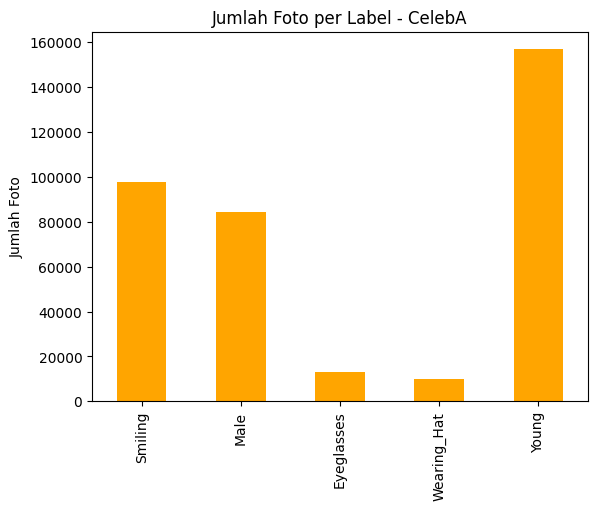

In [10]:
label_cols = ['Smiling', 'Male', 'Eyeglasses', 'Wearing_Hat', 'Young']
for col in label_cols:
    df[col] = (df[col] == 1).astype(int)

print(df[['image_id'] + label_cols].head(10))
print("\nContoh multilabel: 1 foto bisa Smiling=1 dan Male=1 sekaligus")
df[label_cols].sum().plot(kind='bar', color='orange')
plt.title('Jumlah Foto per Label - CelebA')
plt.ylabel('Jumlah Foto')
plt.show()

In [12]:
feature_cols = [c for c in df.columns if c not in ['image_id','partition'] + label_cols + list(attr.columns[1:])]
print("Fitur yang dipakai:", feature_cols)

df_sample = df.sample(20000, random_state=42)
X = df_sample[feature_cols]
y = df_sample[label_cols]

train_mask = df_sample['partition'] == 0
test_mask = df_sample['partition'] == 2
X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

Fitur yang dipakai: ['x_1', 'y_1', 'width', 'height', 'lefteye_x', 'lefteye_y', 'righteye_x', 'righteye_y', 'nose_x', 'nose_y', 'leftmouth_x', 'leftmouth_y', 'rightmouth_x', 'rightmouth_y']
X_train: (15973, 14), X_test: (1945, 14)


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report, accuracy_score, hamming_loss

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = MultiOutputClassifier(LogisticRegression(max_iter=1000))
model.fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)

print("Accuracy (exact match):", accuracy_score(y_test, y_pred))
print("Hamming Loss (makin kecil makin bagus):", hamming_loss(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=label_cols))

Accuracy (exact match): 0.4272493573264782
Hamming Loss (makin kecil makin bagus): 0.17110539845758355
              precision    recall  f1-score   support

     Smiling       0.86      0.84      0.85       990
        Male       0.60      0.45      0.51       766
  Eyeglasses       0.00      0.00      0.00       131
 Wearing_Hat       0.00      0.00      0.00        82
       Young       0.74      1.00      0.85      1438

   micro avg       0.75      0.77      0.76      3407
   macro avg       0.44      0.46      0.44      3407
weighted avg       0.70      0.77      0.72      3407
 samples avg       0.77      0.78      0.74      3407



c:\Users\MyBook Hype AMD\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MyBook Hype AMD\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [14]:
hasil = pd.DataFrame(y_pred[:5], columns=[f"Pred_{c}" for c in label_cols])
asli = y_test.iloc[:5].reset_index(drop=True)
asli.columns = [f"Asli_{c}" for c in label_cols]
print(pd.concat([df_sample[test_mask].iloc[:5][['image_id']].reset_index(drop=True), asli, hasil], axis=1))

hasil_all = pd.DataFrame(y_pred, columns=label_cols)
hasil_all.to_csv('hasil_multilabel_celeba.csv', index=False)
print("Tersimpan: hasil_multilabel_celeba.csv")

print("\n=== KESIMPULAN AKHIR ===")
print("Jenis Klasifikasi: MULTILABEL, karena 1 foto bisa punya banyak label sekaligus")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}, Hamming Loss: {hamming_loss(y_test, y_pred):.4f}")

     image_id  Asli_Smiling  Asli_Male  Asli_Eyeglasses  Asli_Wearing_Hat  \
0  194892.jpg             1          1                0                 0   
1  194074.jpg             1          0                0                 0   
2  191989.jpg             1          0                0                 0   
3  191707.jpg             1          0                0                 0   
4  198822.jpg             0          1                0                 0   

   Asli_Young  Pred_Smiling  Pred_Male  Pred_Eyeglasses  Pred_Wearing_Hat  \
0           0             1          0                0                 0   
1           1             0          1                0                 0   
2           1             1          0                0                 0   
3           1             1          0                0                 0   
4           0             0          0                0                 0   

   Pred_Young  
0           1  
1           1  
2           1  
3         